# Feature engineering and feature selection: will congestion start here in the next 30 minutes?

**Question** (same as `congestion-at-specific-sensor.ipynb`): at a sensor on I-5 northbound, will congestion **start**
in the next 5-30 minutes? Congestion = speed below 40 mph in at least 4 of 6 readings (30 minutes).

**Starting point: the 27 features of that notebook.** Flow `q`, speed `u` and density `k` at the sensor (`i`) and at its
adjacent upstream (`up`) and downstream (`down`) sensors, now and as changes over the last 5 and 10 minutes.

**New features, built on top of them:**

| Group | What it adds |
|---|---|
| differences | contrasts between the three sensors and within the sensor: speed gaps up and down, density gap down, cars piling in (flow up minus flow here) and leaving (flow here minus flow down), acceleration |
| history | the last 30 minutes at the sensor: speed 15 and 30 minutes ago, 15- and 30-minute changes, spread and lowest speed, slow readings, minutes since it was last slow, occupancy change |
| jam ahead | the nearest slow sensor within 5 miles downstream, the lowest speed ahead, and whether that jam is getting closer |
| lanes | how different the lanes are (spread of lane speeds and lane occupancies) |
| time | time of day and weekday |
| place | postmile and number of lanes |
| typical | the sensor's usual speed, occupancy and congestion-start rate at this time, learned from Jan-Jun 2023 only |

**How the features are chosen: three checks, each repeated in 4 time windows** (the 4 quarters of the training year).
A feature has to pass **consistently** (in at least 3 of the 4 windows), not just once:

- **(a) Repeated vote.** In each window, three methods (mutual information, L1-regularized logistic regression, random
  forest importance) each name their top 15; a feature is picked in that window if at least 2 methods name it.
- **(b) Shadow features** (Boruta / GrootCV style). Every feature gets a shuffled copy, which by construction carries no
  signal. A LightGBM model is trained on real and shuffled features together, and each feature's importance (mean
  absolute SHAP value, on a held-out window) is compared with the best shuffled copy. A feature passes in a window if it
  beats all of them; no top-N cut-off is needed.
- **(c) Correlated families: drop and refit.** Features that move together (for example speed now, 15 minutes ago and
  the lowest speed in the last 30 minutes) share credit, so each can look weak on its own. They are grouped into families,
  each family is removed in turn, the model is refit, and AP is measured on the held-out window.

**Final set** = features that pass (a) or (b) consistently, and whose family is needed in (c). Then near-duplicates are
removed, and the result is tested on a later year against the 27 alone, all features, a single one-off vote and two
baselines. SHAP plots then show how each selected feature pushes the prediction up or down.

**Rules**
- Real readings only (`pct_observed` = 100), weekdays without federal holidays, predictions 6:00-19:55.
- Complete rows only: every feature must be a real value, so nothing is ever filled in. Sensors with no real readings
  in Jan-Jun 2023 have no typical values, so they drop out.
- Typical values are learned from Jan-Jun 2023 only.
- Choose on **Jul 2023-Jun 2024**, test on **Jul 2024-Jun 2025**. The Jul-Dec 2025 holdout files are never opened.
- Self-contained: loads the raw files itself and changes nothing else in the repo (results are saved only if
  `SAVE_RESULTS = True`). LightGBM is needed for check (b); without it, (b) is skipped with a message.

## 1. Settings

In [1]:
import time
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
try:
    from lightgbm import LGBMClassifier                      # pip install lightgbm (needed for check (b))
except ImportError:
    LGBMClassifier = None
    print("lightgbm not installed: check (b), shadow features, is skipped")

# the question (same as congestion-at-specific-sensor.ipynb)
HORIZON = 6              # readings ahead: congestion starting in the next 5-30 minutes
CONGESTED_MPH = 40       # a reading is slow below 40 mph ...
WINDOW = 6               # ... and congestion = at least 4 of 6 readings slow
MIN_SLOW = 4

# data and periods
DAY_START, DAY_END = 6, 20                                # predictions 6:00-19:55
MIN_OBSERVED = 100                                        # real readings only
TYPICAL_START, TYPICAL_END = "2023-01-01", "2023-07-01"   # typical values learned here only
TRAIN_START, TRAIN_END = "2023-07-01", "2024-07-01"       # choose the features (and train) on this year
TEST_END = "2025-07-01"                                   # test on Jul 2024 - Jun 2025
HOLDOUT_START = "2025-07-01"                              # files from this date on are never opened
AHEAD_MILES = 5                                           # how far ahead the jam-ahead features look

# feature selection
SELECTION_WINDOWS = [("2023-07-01", "2023-10-01"), ("2023-10-01", "2024-01-01"),
                     ("2024-01-01", "2024-04-01"), ("2024-04-01", "2024-07-01")]   # the 4 quarters of the training year
MIN_WINDOWS = 3          # "consistently" = in at least 3 of the 4 windows
TOP_N = 15               # check (a): each method names its top 15
ROWS_PER_SENSOR = 1_500  # check (a): up to this many rows per sensor and window
FIT_SAMPLE = 100_000     # checks (b) and (c): training rows per fit (random sample)
FAMILY_CORR = 0.8        # check (c): features correlated above this are one family
CHECK_TREES = 150        # checks (b) and (c): boosting trees per fit

# test models
MODEL_SAMPLE = 300_000   # training rows for the test models (random sample)
N_TREES = 300            # gradient boosting trees
SAVE_RESULTS = False     # True = also save the result tables to <repo>/results/congestion_start_features/

warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load the data

Finds the repo folder (the one that contains `Data/D12 2023`) and reads each weekday file from Jan 2023 to Jun 2025:
mainline sensors, real readings only, 5:00-20:55 (one extra hour on each side, for history and outcomes). The spread of
lane speeds and lane occupancies is computed while reading, so the per-lane columns are not kept. Takes a few minutes.

In [2]:
MARKER = Path("Data") / "D12 2023" / "pems_parquet_stations.csv"
ROOT = Path.cwd()
while not (ROOT / MARKER).exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / MARKER).exists():
    raise FileNotFoundError("Couldn't find Data/D12 2023 above " + str(Path.cwd()) + ". Open the notebook inside the repo.")
DATA_DIR = ROOT / "Data"
print("repo folder:", ROOT)

holidays = set(USFederalHolidayCalendar().holidays("2023-01-01", "2025-12-31").date)
lane_speed_cols = [f"lane{k}_speed" for k in range(1, 9)]
lane_occ_cols = [f"lane{k}_occupancy" for k in range(1, 9)]
columns = ["timestamp", "station", "speed", "flow", "occupancy", "pct_observed"] + lane_speed_cols + lane_occ_cols

files = sorted(DATA_DIR.glob("D12 */pems_parquet/station_5min/d12_text_station_5min_*.parquet"))
holdout_day = pd.Timestamp(HOLDOUT_START).date()
parts, used, skipped = [], 0, 0
start_clock = time.time()
for i, path in enumerate(files, start=1):
    day = datetime.strptime(path.stem[-10:], "%Y_%m_%d").date()
    if day >= holdout_day:
        skipped += 1                       # holdout: never opened
        continue
    if day.weekday() >= 5 or day in holidays:
        continue
    part = pd.read_parquet(path, columns=columns, filters=[("lane_type", "==", "ML")])
    hour = part["timestamp"].dt.hour
    part = part[(hour >= DAY_START - 1) & (hour <= DAY_END) & (part["pct_observed"] >= MIN_OBSERVED)].copy()
    part["lane_speed_spread"] = part[lane_speed_cols].std(axis=1)      # how different the lanes' speeds are
    part["lane_occ_spread"] = part[lane_occ_cols].std(axis=1)
    parts.append(part[["timestamp", "station", "speed", "flow", "occupancy", "lane_speed_spread", "lane_occ_spread"]])
    used += 1
    if i % 200 == 0:
        print(f"read {i}/{len(files)} files ({time.time() - start_clock:.0f}s)")

main = pd.concat(parts, ignore_index=True)
del parts
main = main.drop_duplicates(["station", "timestamp"])                 # a few days have duplicated rows
print(f"{used} weekdays used, {skipped} holdout files skipped | real mainline readings: {len(main):,}")

repo folder: /tmp/claude-0/-home-claude/780780e6-0102-5b34-968b-ee52f80f838b/scratchpad/loadtest/repo


read 200/1094 files (3s)


read 600/1094 files (8s)


read 800/1094 files (11s)


624 weekdays used, 182 holdout files skipped | real mainline readings: 3,083,319


In [3]:
# sensors in road order (northbound: postmile grows in the direction of travel)
meta = pd.read_csv(DATA_DIR / "D12 2023" / "pems_parquet_stations.csv")
mainline = meta[(meta["Fwy"] == 5) & (meta["Type"] == "ML") & (meta["Dir"] == "N") & meta["ID"].isin(main["station"].unique())]
mainline = mainline.sort_values("Abs_PM")
ids = mainline["ID"].tolist()
postmile = dict(zip(mainline["ID"], mainline["Abs_PM"]))
lanes_of = dict(zip(mainline["ID"], mainline["Lanes"]))
name_of = dict(zip(mainline["ID"], mainline["Name"]))
print(len(ids), "northbound mainline sensors, postmile", min(postmile.values()), "to", max(postmile.values()))

43 northbound mainline sensors, postmile 99.811 to 116.601


## 3. Wide tables: one row per 5-minute slot, one column per sensor

Every 5-minute slot is present, so `shift(1)` always means 5 minutes earlier. A slot without a real reading is empty.
Density = flow per hour / speed (vehicles per mile).

In [4]:
all_times = pd.date_range("2023-01-01 00:00", "2025-06-30 23:55", freq="5min")


def wide(column):
    table = main.pivot(index="timestamp", columns="station", values=column)
    return table.reindex(index=all_times, columns=ids)


speed = wide("speed")
flow = wide("flow") * 12                      # vehicles per hour
occ = wide("occupancy")
density = flow / speed.where(speed > 0)
lane_speed_spread = wide("lane_speed_spread")
lane_occ_spread = wide("lane_occ_spread")
print(speed.shape, "| share of empty cells:", round(speed.isna().mean().mean(), 3))

(262656, 43) | share of empty cells: 0.727


## 4. The label

As in `congestion-at-specific-sensor.ipynb`: congested at time s if at least 4 of the 6 readings from s to s+25 min are
below 40 mph; a congestion **start** is the first such s after a non-congested one. Label 1 if a start happens in the
next 5-30 minutes. A label counts only if every reading it depends on is real.

In [5]:
slow = (speed < CONGESTED_MPH).astype(int)
slow_count = slow.rolling(WINDOW).sum().shift(-(WINDOW - 1))      # slow readings from t to t+25 min
congested = slow_count >= MIN_SLOW
starts = congested & ~congested.shift(1, fill_value=False)

label = pd.DataFrame(False, index=all_times, columns=ids)
for h in range(1, HORIZON + 1):
    label = label | starts.shift(-h, fill_value=False)

known = speed.notna()
for k in range(1, HORIZON + WINDOW):
    known = known & speed.shift(-k).notna()

minutes_of_day = all_times.hour * 60 + all_times.minute
in_window = (all_times.hour >= DAY_START) & (all_times.hour < DAY_END)
print(f"congestion starts: {int(starts.sum().sum()):,} | share of checkable daytime rows labelled 1: "
      f"{label[known & in_window[:, None]].sum().sum() / (known & in_window[:, None]).sum().sum():.2%}")

congestion starts: 12,265 | share of checkable daytime rows labelled 1: 2.69%


## 5. Typical values (learned from Jan-Jun 2023 only)

- **typical speed / occupancy:** the sensor's average real value by weekday and 5-minute slot
- **typical start rate:** how often a congestion start followed (label 1) at this sensor and 5-minute slot (weekdays pooled)

Training starts in July 2023, so these never contain a training or validation day.

In [6]:
dow = all_times.dayofweek
slot = all_times.hour * 12 + all_times.minute // 5
typical_rows = (all_times >= TYPICAL_START) & (all_times < TYPICAL_END)
keys = pd.MultiIndex.from_arrays([dow, slot])


def typical_by_weekday_and_slot(table):
    average = table[typical_rows].groupby([dow[typical_rows], slot[typical_rows]]).mean()
    looked_up = average.reindex(keys)
    looked_up.index = all_times
    return looked_up


typical_speed = typical_by_weekday_and_slot(speed)
typical_occ = typical_by_weekday_and_slot(occ)

label_known = label.astype(float).where(known)
start_rate = label_known[typical_rows].groupby(slot[typical_rows]).mean()
typical_start_rate = start_rate.reindex(slot)
typical_start_rate.index = all_times
print("typical start rate, busiest slot per sensor (median over sensors):", round(typical_start_rate.max().median(), 3))

typical start rate, busiest slot per sensor (median over sensors): 0.133


## 6. Build the features

One table per sensor, then stacked. A row is kept if it is a weekday 6:00-19:55 slot from July 2023 on, the label can be
checked, and **every feature is real** (complete rows only, so nothing is ever filled in).

In [7]:
CORE_27 = [f"{name}_{where}" for where in ["i", "up", "down"]
           for name in ["q", "dq1", "dq2", "u", "du1", "du2", "k", "dk1", "dk2"]]
GROUPS = {
    "27 features": CORE_27,
    "differences": ["gap_up_speed", "gap_down_speed", "gap_down_density", "inflow_up", "outflow_down", "accel_i"],
    "history": ["u_lag_15", "u_lag_30", "du3_i", "du6_i", "speed_std_30", "speed_min_30", "slow_last_30",
                "minutes_since_slow", "occ_change_15"],
    "jam ahead": ["jam_miles_ahead", "min_speed_ahead", "jam_miles_change_10"],
    "lanes": ["lane_speed_spread", "lane_occ_spread"],
    "time": ["tod_sin", "tod_cos", "day_of_week"],
    "place": ["abs_pm", "lanes"],
    "typical": ["typical_speed_now", "typical_speed_target", "speed_vs_typical", "occ_vs_typical", "typical_start_rate"],
}
ALL_FEATURES = [f for group in GROUPS.values() for f in group]
REFERENCE = CORE_27
print(len(ALL_FEATURES), "features:", len(CORE_27), "starting +", len(ALL_FEATURES) - len(CORE_27), "new, in",
      len(GROUPS) - 1, "new groups")

keep_time = in_window & (all_times >= TRAIN_START)
tables = []
start_clock = time.time()
for i, sid in enumerate(ids):
    s = speed[sid]
    df = pd.DataFrame(index=all_times)

    # --- the 27 starting features: sensor (i) and its adjacent upstream / downstream sensors
    for where, j in [("i", i), ("up", i - 1), ("down", i + 1)]:
        for name, table in [("q", flow), ("u", speed), ("k", density)]:
            if 0 <= j < len(ids):
                values = table[ids[j]]
            else:                                                    # first / last sensor: no neighbor
                values = pd.Series(np.nan, index=all_times)
            df[f"{name}_{where}"] = values
            df[f"d{name}1_{where}"] = values - values.shift(1)       # change over the last 5 minutes
            df[f"d{name}2_{where}"] = values - values.shift(2)       # change over the last 10 minutes

    # --- differences between the three sensors, and within the sensor
    df["gap_up_speed"] = df["u_up"] - df["u_i"]
    df["gap_down_speed"] = df["u_down"] - df["u_i"]                  # negative = slower downstream
    df["gap_down_density"] = df["k_down"] - df["k_i"]
    df["inflow_up"] = df["q_up"] - df["q_i"]                         # more cars arriving than passing
    df["outflow_down"] = df["q_i"] - df["q_down"]
    df["accel_i"] = df["du1_i"] - (df["du2_i"] - df["du1_i"])        # is the slowdown speeding up?

    # --- history: the last 30 minutes at the sensor (1 slot = 5 minutes)
    df["u_lag_15"] = s.shift(3)
    df["u_lag_30"] = s.shift(6)
    df["du3_i"] = s - s.shift(3)
    df["du6_i"] = s - s.shift(6)
    df["speed_std_30"] = s.rolling(6).std()                          # empty unless all 6 readings are real
    df["speed_min_30"] = s.rolling(6).min()
    df["slow_last_30"] = (s < CONGESTED_MPH).astype(float).where(s.notna()).rolling(6).sum()
    last_slow = pd.Series(np.where(s < CONGESTED_MPH, all_times, pd.NaT), index=all_times).ffill()
    since = (pd.Series(all_times, index=all_times) - last_slow).dt.total_seconds() / 60
    df["minutes_since_slow"] = since.clip(upper=120).fillna(120)      # capped at 2 hours
    df["occ_change_15"] = occ[sid] - occ[sid].shift(3)

    # --- jam ahead: sensors up to AHEAD_MILES downstream
    ahead = [nid for nid in ids if 0 < postmile[nid] - postmile[sid] <= AHEAD_MILES]
    if ahead:
        miles = pd.Series({nid: postmile[nid] - postmile[sid] for nid in ahead})
        slow_ahead = speed[ahead] < CONGESTED_MPH                     # an estimated reading counts as not slow
        jam = slow_ahead.mul(miles, axis=1).where(slow_ahead).min(axis=1).fillna(AHEAD_MILES)
        df["jam_miles_ahead"] = jam
        df["min_speed_ahead"] = speed[ahead].min(axis=1)
        df["jam_miles_change_10"] = jam - jam.shift(2)               # negative = the jam is getting closer
    else:                                                            # end of the corridor: nothing ahead
        df["jam_miles_ahead"] = np.nan
        df["min_speed_ahead"] = np.nan
        df["jam_miles_change_10"] = np.nan

    # --- lanes
    df["lane_speed_spread"] = lane_speed_spread[sid]
    df["lane_occ_spread"] = lane_occ_spread[sid]

    # --- time and place
    df["tod_sin"] = np.sin(2 * np.pi * minutes_of_day / 1440)
    df["tod_cos"] = np.cos(2 * np.pi * minutes_of_day / 1440)
    df["day_of_week"] = dow
    df["abs_pm"] = postmile[sid]
    df["lanes"] = lanes_of[sid]

    # --- typical (learned from Jan-Jun 2023)
    df["typical_speed_now"] = typical_speed[sid]
    df["typical_speed_target"] = typical_speed[sid].shift(-6)        # typical speed 30 minutes from now
    df["speed_vs_typical"] = s - typical_speed[sid]
    df["occ_vs_typical"] = occ[sid] - typical_occ[sid]
    df["typical_start_rate"] = typical_start_rate[sid]

    # --- label, and which rows to keep: complete rows only (every feature real)
    df["label"] = label[sid].astype(int)
    keep = keep_time & known[sid].to_numpy() & df[ALL_FEATURES].notna().all(axis=1).to_numpy()
    df = df[keep]
    df[ALL_FEATURES] = df[ALL_FEATURES].astype("float32")
    df["station"] = sid
    tables.append(df.rename_axis("timestamp").reset_index())

data = pd.concat(tables, ignore_index=True)
del tables
# the label uses readings up to 55 minutes ahead; windows are split on this time so no label crosses a boundary
data["label_time"] = data["timestamp"] + pd.Timedelta(minutes=5 * (HORIZON + WINDOW - 1))
print(f"{len(data):,} rows | label share {data['label'].mean():.2%} | built in {time.time() - start_clock:.0f}s")
print("rows per year:", data["timestamp"].dt.year.value_counts().sort_index().to_dict())

57 features: 27 starting + 30 new, in 7 new groups


747,586 rows | label share 2.58% | built in 20s
rows per year: {2023: 110090, 2024: 433570, 2025: 203926}


## 7. Training and test rows, and the 4 selection windows

- **Training year:** Jul 2023-Jun 2024. **Test year:** Jul 2024-Jun 2025. A row belongs to a period only if its label
  (which looks up to 55 minutes ahead) is complete inside that period.
- **Selection windows:** the 4 quarters of the training year. Checks (b) and (c) hold out one window at a time and fit
  on the other three (blocked cross-validation). This only decides which features help; the test on the later year is
  strictly forward in time.

In [8]:
train_all = data[(data["timestamp"] >= TRAIN_START) & (data["label_time"] < TRAIN_END)].reset_index(drop=True)
test_all = data[(data["timestamp"] >= TRAIN_END) & (data["label_time"] < TEST_END)].reset_index(drop=True)
window_names = [f"{a[:7]} to {b[:7]}" for a, b in SELECTION_WINDOWS]
window_of = pd.Series(pd.NA, index=train_all.index, dtype="object")
for name, (a, b) in zip(window_names, SELECTION_WINDOWS):
    window_of[(train_all["timestamp"] >= a) & (train_all["label_time"] < b)] = name
train_all["window"] = window_of

print(f"training rows: {len(train_all):,} (label share {train_all['label'].mean():.2%})")
print(f"test rows:     {len(test_all):,} (label share {test_all['label'].mean():.2%})")
train_all.groupby("window")["label"].agg(rows="size", label_share="mean").round(4)

training rows: 372,092 (label share 2.40%)
test rows:     375,494 (label share 2.75%)


,rows,label_share
window,,
2023-07 to 2023-10,20866,0.0141
2023-10 to 2024-01,89224,0.0267
2024-01 to 2024-04,146668,0.0241
2024-04 to 2024-07,115334,0.0236


## 8. How correlated are the features?

Pearson correlation between every pair of features, on a sample of training rows. Some are exact combinations of others by
construction (for example `du3_i` = `u_i` - `u_lag_15`): trees split more easily on a difference than on two separate
values, so both are built and the checks decide.

In [9]:
corr_sample = train_all.sample(min(100_000, len(train_all)), random_state=0)
corr = corr_sample[ALL_FEATURES].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("correlation").reset_index().rename(columns={"level_0": "feature 1", "level_1": "feature 2"}))
pairs = pairs.reindex(pairs["correlation"].abs().sort_values(ascending=False).index)
print("pairs with |correlation| above", FAMILY_CORR, ":", int((pairs["correlation"].abs() > FAMILY_CORR).sum()))
pairs.head(15).round(3)

pairs with |correlation| above 0.8 : 40


,feature 1,feature 2,correlation
1919,u_lag_15,speed_min_30,0.973
209,u_i,speed_min_30,0.958
1976,u_lag_30,speed_min_30,0.945
1915,u_lag_15,u_lag_30,0.944
204,u_i,u_lag_15,0.943
3017,typical_speed_now,typical_speed_target,0.942
205,u_i,u_lag_30,0.885
2263,slow_last_30,minutes_since_slow,-0.883
2218,speed_min_30,typical_speed_now,0.867
223,u_i,typical_speed_now,0.866


## 9. Check (a): the vote, repeated in each window

In each window: up to `ROWS_PER_SENSOR` rows per sensor; each method names its top 15; a feature is **picked** in that
window if at least 2 of the 3 methods name it. It **passes (a)** if it is picked in at least 3 of the 4 windows.

The same vote run once on the whole training year (the earlier, one-off version) is kept for comparison in section 13.

In [10]:
def vote(rows, seed=0):
    """Run the three methods on these rows; return how many of them picked each feature (0-3)."""
    shuffled = rows.sample(frac=1, random_state=seed)
    s = shuffled[shuffled.groupby("station").cumcount() < ROWS_PER_SENSOR].sort_values("timestamp")

    small = s.sample(min(30_000, len(s)), random_state=seed)
    mi = pd.Series(mutual_info_classif(small[ALL_FEATURES], small["label"], random_state=seed), index=ALL_FEATURES)

    small_l1 = s.sample(min(30_000, len(s)), random_state=seed + 1).sort_values("timestamp")
    X_scaled = StandardScaler().fit_transform(small_l1[ALL_FEATURES])
    l1 = LogisticRegressionCV(Cs=np.logspace(-3, 0, 6), penalty="l1", solver="liblinear", cv=TimeSeriesSplit(n_splits=3),
                              scoring="average_precision", class_weight="balanced", max_iter=1000, n_jobs=-1,
                              random_state=seed).fit(X_scaled, small_l1["label"])
    l1_weight = pd.Series(np.abs(l1.coef_[0]), index=ALL_FEATURES)

    rf = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=20, max_samples=min(50_000, len(s)),
                                class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
    rf.fit(s[ALL_FEATURES], s["label"])
    rf_importance = pd.Series(rf.feature_importances_, index=ALL_FEATURES)

    tops = [set(mi.nlargest(TOP_N).index),
            set(l1_weight[l1_weight > 0].nlargest(TOP_N).index),
            set(rf_importance.nlargest(TOP_N).index)]
    return pd.Series([sum(f in t for t in tops) for f in ALL_FEATURES], index=ALL_FEATURES)


start_clock = time.time()
votes = pd.DataFrame({name: vote(train_all[train_all["window"] == name]) for name in window_names})
picked = votes >= 2
check_a = picked.sum(axis=1)
pass_a = check_a >= MIN_WINDOWS
print(f"done in {time.time() - start_clock:.0f}s | {int(pass_a.sum())} features pass (a)")

one_off_votes = vote(train_all)                                    # the one-off vote, for comparison only
one_off = list(one_off_votes.index[one_off_votes >= 2])

group_of = {f: g for g, cols in GROUPS.items() for f in cols}
table_a = votes.assign(windows_picked=check_a, passes_a=pass_a, group=lambda t: t.index.map(group_of))
table_a[table_a["windows_picked"] > 0].sort_values("windows_picked", ascending=False)

done in 198s | 14 features pass (a)


,2023-07 to 2023-10,2023-10 to 2024-01,2024-01 to 2024-04,2024-04 to 2024-07,windows_picked,passes_a,group
u_i,2,2,2,2,4,True,27 features
k_i,3,3,3,3,4,True,27 features
typical_speed_target,3,3,3,3,4,True,typical
u_down,3,3,3,3,4,True,27 features
u_lag_15,2,2,2,2,4,True,history
k_down,2,3,2,2,4,True,27 features
speed_min_30,2,2,3,3,4,True,history
typical_speed_now,3,2,2,2,4,True,typical
min_speed_ahead,2,3,3,2,4,True,jam ahead
minutes_since_slow,2,2,2,2,4,True,history


## 10. Check (b): shadow features

For each window in turn: a LightGBM model is trained on the other three windows with every feature **and** a shuffled
copy of every feature (shuffling breaks any link to the label). Importance = mean absolute SHAP value on the held-out
window (LightGBM computes SHAP values itself). A feature **beats the shadows** in that window if its importance is above
the most important shuffled copy. It **passes (b)** if it does so in at least 3 of the 4 windows.

Pruned trees (depth 6) are used, as recommended for shadow-feature methods.

In [11]:
def shadow_importance(train_rows, val_rows, seed):
    rng = np.random.default_rng(seed)
    shadow_names = ["shadow_" + f for f in ALL_FEATURES]

    def with_shadows(rows):
        real = rows[ALL_FEATURES].reset_index(drop=True)
        shadows = pd.DataFrame({s: rng.permutation(real[f].to_numpy()) for f, s in zip(ALL_FEATURES, shadow_names)})
        return pd.concat([real, shadows], axis=1)

    model = LGBMClassifier(n_estimators=CHECK_TREES, learning_rate=0.05, num_leaves=31, max_depth=6,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=seed)
    model.fit(with_shadows(train_rows), train_rows["label"])
    shap_values = model.predict(with_shadows(val_rows), pred_contrib=True)[:, :-1]     # last column = baseline
    importance = pd.Series(np.abs(shap_values).mean(axis=0), index=ALL_FEATURES + shadow_names)
    return importance[ALL_FEATURES], importance[shadow_names].max()


if LGBMClassifier is not None:
    start_clock = time.time()
    shadow_rows, beats = {}, {}
    for k, name in enumerate(window_names):
        others = train_all[(train_all["window"] != name) & train_all["window"].notna()]
        held_out = train_all[train_all["window"] == name]
        others = others.sample(min(FIT_SAMPLE, len(others)), random_state=k)
        held_out = held_out.sample(min(30_000, len(held_out)), random_state=k)
        real, best_shadow = shadow_importance(others, held_out, seed=k)
        shadow_rows[name] = real / best_shadow                      # above 1 = beats every shuffled copy
        beats[name] = real > best_shadow
    shadow_ratio = pd.DataFrame(shadow_rows)
    check_b = pd.DataFrame(beats).sum(axis=1)
    pass_b = check_b >= MIN_WINDOWS
    print(f"done in {time.time() - start_clock:.0f}s | {int(pass_b.sum())} features pass (b)")
    table_b = shadow_ratio.round(2).assign(windows_beaten=check_b, passes_b=pass_b, group=lambda t: t.index.map(group_of))
    display(table_b.sort_values("windows_beaten", ascending=False).head(25))
else:
    check_b = pd.Series(0, index=ALL_FEATURES)
    pass_b = pd.Series(False, index=ALL_FEATURES)
    print("check (b) skipped: lightgbm is not installed")

done in 60s | 11 features pass (b)


,2023-07 to 2023-10,2023-10 to 2024-01,2024-01 to 2024-04,2024-04 to 2024-07,windows_beaten,passes_b,group
u_i,2.13,3.30,3.07,2.62,4,True,27 features
k_i,7.86,7.40,7.44,7.06,4,True,27 features
k_down,7.97,2.15,9.31,6.73,4,True,27 features
min_speed_ahead,13.13,9.14,11.79,13.29,4,True,jam ahead
abs_pm,4.06,1.63,5.34,7.39,4,True,place
typical_start_rate,15.77,13.59,16.02,16.87,4,True,typical
tod_sin,2.55,1.81,2.83,2.63,4,True,time
typical_speed_target,18.69,12.84,23.52,13.83,4,True,typical
outflow_down,2.88,1.25,2.51,1.54,4,True,differences
tod_cos,1.39,1.46,0.90,1.80,3,True,time


## 11. Check (c): correlated families, drop and refit

**Candidates** = features that pass (a) or (b). Candidates that all correlate above `FAMILY_CORR` with each other form a
**family** (complete-linkage clustering, so a family is never a long chain of loosely related features). For each window in turn: fit gradient boosting on the other three windows with all candidates,
then again without one family, and compare AP on the held-out window. A family is **needed** if dropping it lowers AP
in at least 3 of the 4 windows (and on average).

In [12]:
candidates = [f for f in ALL_FEATURES if pass_a[f] or pass_b[f]]
c = corr.loc[candidates, candidates].abs()

# complete-linkage clustering: within a family, EVERY pair correlates above FAMILY_CORR (no long chains)
if len(candidates) > 1:
    distance = 1 - c.to_numpy()
    np.fill_diagonal(distance, 0)
    tree = linkage(squareform(distance, checks=False), method="complete")
    cluster = fcluster(tree, t=1 - FAMILY_CORR, criterion="distance")
else:
    cluster = np.ones(len(candidates), dtype=int)
families = [[f for f, k in zip(candidates, cluster) if k == label] for label in pd.unique(cluster)]
family_name = {f"family {k + 1}": fam for k, fam in enumerate(families)}
print(len(candidates), "candidates in", len(families), "families:")
for name, fam in family_name.items():
    print(f"   {name}: {fam}")


def ap_held_out(train_rows, val_rows, features):
    model = HistGradientBoostingClassifier(max_iter=CHECK_TREES, learning_rate=0.1, early_stopping=False, random_state=0)
    model.fit(train_rows[features], train_rows["label"])
    return average_precision_score(val_rows["label"], model.predict_proba(val_rows[features])[:, 1])


start_clock = time.time()
drop_rows = []
for k, name in enumerate(window_names):
    others = train_all[(train_all["window"] != name) & train_all["window"].notna()]
    others = others.sample(min(FIT_SAMPLE, len(others)), random_state=k)
    held_out = train_all[train_all["window"] == name]
    base = ap_held_out(others, held_out, candidates)
    for fam_name, fam in family_name.items():
        rest = [f for f in candidates if f not in fam]
        drop_rows.append({"window": name, "family": fam_name, "AP lost when dropped": base - ap_held_out(others, held_out, rest)})
drops = pd.DataFrame(drop_rows).pivot(index="family", columns="window", values="AP lost when dropped")[window_names]
drops = drops.reindex(family_name.keys())
drops["windows_where_it_helped"] = (drops[window_names] > 0).sum(axis=1)
drops["mean AP lost"] = drops[window_names].mean(axis=1)
drops["needed"] = (drops["windows_where_it_helped"] >= MIN_WINDOWS) & (drops["mean AP lost"] > 0)
drops["members"] = [", ".join(family_name[n]) for n in drops.index]
print(f"done in {time.time() - start_clock:.0f}s")
drops.round(4)

16 candidates in 11 families:
   family 1: ['q_i']
   family 2: ['u_i', 'u_lag_15', 'speed_min_30', 'minutes_since_slow']
   family 3: ['k_i']
   family 4: ['u_down', 'min_speed_ahead']
   family 5: ['k_down']
   family 6: ['outflow_down']
   family 7: ['tod_sin']
   family 8: ['tod_cos']
   family 9: ['abs_pm']
   family 10: ['typical_speed_now', 'typical_speed_target']
   family 11: ['typical_start_rate']


done in 72s


window,2023-07 to 2023-10,2023-10 to 2024-01,2024-01 to 2024-04,2024-04 to 2024-07,windows_where_it_helped,mean AP lost,needed,members
family,,,,,,,,
family 1,-0.0228,-0.0081,-0.0015,0.0026,1,-0.0075,False,q_i
family 2,0.0257,0.0468,0.0102,0.0087,4,0.0229,True,"u_i, u_lag_15, speed_min_30, minutes_since_slow"
family 3,-0.0069,-0.0134,0.0020,0.0150,2,-0.0008,False,k_i
family 4,0.0677,-0.0150,-0.0013,0.0347,2,0.0215,False,"u_down, min_speed_ahead"
family 5,0.0338,-0.0101,0.0016,0.0051,3,0.0076,True,k_down
family 6,0.0636,-0.0018,0.0120,0.0069,3,0.0202,True,outflow_down
family 7,0.0407,-0.0020,-0.0017,0.0019,2,0.0098,False,tod_sin
family 8,-0.0041,-0.0104,0.0128,-0.0027,1,-0.0011,False,tod_cos
family 9,0.0195,-0.0042,-0.0016,0.0243,2,0.0095,False,abs_pm


## 12. The final set

Candidates whose family is needed. Then, as before, if two of them correlate above 0.95, the one less correlated with the
label is dropped.

In [13]:
needed_families = [n for n in drops.index if drops.loc[n, "needed"]]
kept = [f for f in candidates if any(f in family_name[n] for n in needed_families)] or candidates

corr_kept = corr.loc[kept, kept].abs()
corr_with_label = corr_sample[kept].corrwith(corr_sample["label"]).abs()
selected = list(kept)
for a in kept:
    for b in kept:
        if a < b and a in selected and b in selected and corr_kept.loc[a, b] > 0.95:
            weaker = a if corr_with_label[a] < corr_with_label[b] else b
            selected.remove(weaker)
            print(f"{a} and {b} correlate {corr_kept.loc[a, b]:.2f}: dropped {weaker}")

summary = pd.DataFrame({"group": [group_of[f] for f in ALL_FEATURES],
                        "(a) windows picked": check_a, "(b) windows beating shadows": check_b,
                        "candidate": [f in candidates for f in ALL_FEATURES],
                        "selected": [f in selected for f in ALL_FEATURES]}, index=ALL_FEATURES)
print(len(selected), "selected features:", selected)
print("from groups:", summary.loc[selected, "group"].value_counts().to_dict())
summary[summary["candidate"]].sort_values(["selected", "(a) windows picked", "(b) windows beating shadows"], ascending=False)

speed_min_30 and u_i correlate 0.96: dropped u_i
speed_min_30 and u_lag_15 correlate 0.97: dropped u_lag_15
6 selected features: ['k_down', 'outflow_down', 'speed_min_30', 'minutes_since_slow', 'typical_speed_now', 'typical_speed_target']
from groups: {'history': 2, 'typical': 2, '27 features': 1, 'differences': 1}


,group,(a) windows picked,(b) windows beating shadows,candidate,selected
k_down,27 features,4,4,True,True
typical_speed_target,typical,4,4,True,True
typical_speed_now,typical,4,3,True,True
speed_min_30,history,4,2,True,True
minutes_since_slow,history,4,0,True,True
outflow_down,differences,0,4,True,True
u_i,27 features,4,4,True,False
k_i,27 features,4,4,True,False
min_speed_ahead,jam ahead,4,4,True,False
abs_pm,place,4,4,True,False


## 13. Test on Jul 2024-Jun 2025: do the selected features work?

All models are gradient boosting, trained on a random sample of the training year and scored on every test row:
- **baseline: speed now:** the slower the road now, the higher the risk (no model)
- **baseline: typical start rate:** how often a start followed at this sensor and time in Jan-Jun 2023 (no model)
- **the 27 features** (the starting point)
- **all features**
- **one-off vote:** features picked by at least 2 methods in a single vote on the whole training year
- **selected (consistent):** the final set from section 12

**Measures:** AP (average precision; random guessing scores the share of label-1 rows), ROC-AUC, and precision at 80%
recall (the share of warnings that are right when the cutoff is set to catch 80% of the rows followed by a start). Also
shown per half-year, to see whether results hold over time.

In [14]:
def make_model():
    return HistGradientBoostingClassifier(max_iter=N_TREES, learning_rate=0.05, early_stopping=False, random_state=0)


def measures(y, score):
    p, r, _ = precision_recall_curve(y, score)
    return {"AP": average_precision_score(y, score), "ROC-AUC": roc_auc_score(y, score),
            "precision at 80% recall": p[r >= 0.8].max()}


train_sample = train_all.sample(min(MODEL_SAMPLE, len(train_all)), random_state=0)
y_test = test_all["label"].to_numpy()
scores_by_set = {
    "baseline: speed now": (-test_all["u_i"]).to_numpy(),
    "baseline: typical start rate": test_all["typical_start_rate"].to_numpy(),
}
feature_sets = {"the 27 features": CORE_27, "all features": ALL_FEATURES, "one-off vote": one_off,
                "selected (consistent)": selected}
models = {}
for name, features in feature_sets.items():
    models[name] = make_model().fit(train_sample[features], train_sample["label"])
    scores_by_set[name] = models[name].predict_proba(test_all[features])[:, 1]

half = np.where(test_all["timestamp"] < "2025-01-01", "Jul-Dec 2024", "Jan-Jun 2025")
rows = []
for name, score in scores_by_set.items():
    row = {"set": name, "features": len(feature_sets.get(name, []))}
    row.update(measures(y_test, score))
    for h in ["Jul-Dec 2024", "Jan-Jun 2025"]:
        row[f"AP {h}"] = average_precision_score(y_test[half == h], score[half == h])
    rows.append(row)
test_table = pd.DataFrame(rows).set_index("set")
print(f"random guessing: AP = {y_test.mean():.3f}")
test_table.round(3)

random guessing: AP = 0.027


,features,AP,ROC-AUC,precision at 80% recall,AP Jul-Dec 2024,AP Jan-Jun 2025
set,,,,,,
baseline: speed now,0,0.059,0.775,0.060,0.062,0.057
baseline: typical start rate,0,0.253,0.909,0.199,0.255,0.252
the 27 features,27,0.305,0.932,0.178,0.291,0.319
all features,57,0.462,0.960,0.300,0.467,0.459
one-off vote,15,0.458,0.958,0.294,0.461,0.457
selected (consistent),6,0.403,0.949,0.252,0.408,0.401


## 14. Permutation importance (test year)

Shuffle one selected feature at a time on 40,000 test rows and measure how much AP falls. Correlated features share
credit, so a feature with a close partner looks less important than it is (check (c) measures families as a whole).

In [15]:
group_colors = dict(zip(GROUPS, ["#256abf", "#7fb3e6", "#e07b39", "#c7a32a", "#5a9e5a", "#8f6bb3", "#b36b8f", "#5f6b7a"]))
part = test_all.sample(min(40_000, len(test_all)), random_state=0)
result = permutation_importance(models["selected (consistent)"], part[selected], part["label"],
                                scoring="average_precision", n_repeats=3, random_state=0)
importance = pd.Series(result.importances_mean, index=selected).sort_values(ascending=False)
importance.round(4).to_frame("AP lost when shuffled").assign(group=lambda t: t.index.map(group_of))

,AP lost when shuffled,group
typical_speed_target,0.3741,typical
typical_speed_now,0.1641,typical
speed_min_30,0.1621,history
k_down,0.1369,27 features
minutes_since_slow,0.1190,history
outflow_down,0.0618,differences


## 15. SHAP: how each feature pushes the prediction

SHAP values split each prediction into one contribution per feature: how much that feature pushed the predicted risk up
(positive) or down (negative) for that row, compared with an average row (in log-odds, the model's internal scale).
They are computed with a LightGBM model on the selected features (LightGBM calculates SHAP values itself, so the `shap`
package is not needed), on 20,000 test rows.

- **Mean |SHAP|:** how much a feature moves predictions on average (overall importance).
- **Beeswarm:** one dot per row. Left/right = lowers/raises the risk; colour = the feature's value (blue low, red high).
  For example, red dots on the right mean "high values raise the risk".
- **Dependence plots:** for the 4 most important features, how the contribution changes with the feature's value.

LightGBM on the selected features: test AP 0.401 (gradient boosting above: 0.403)


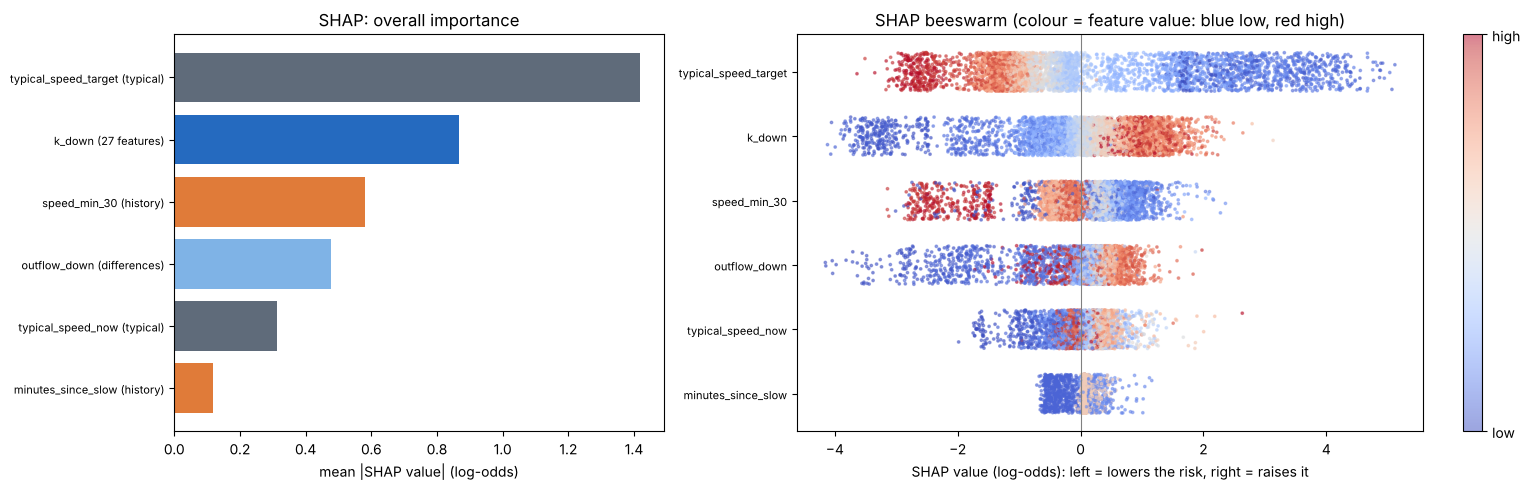

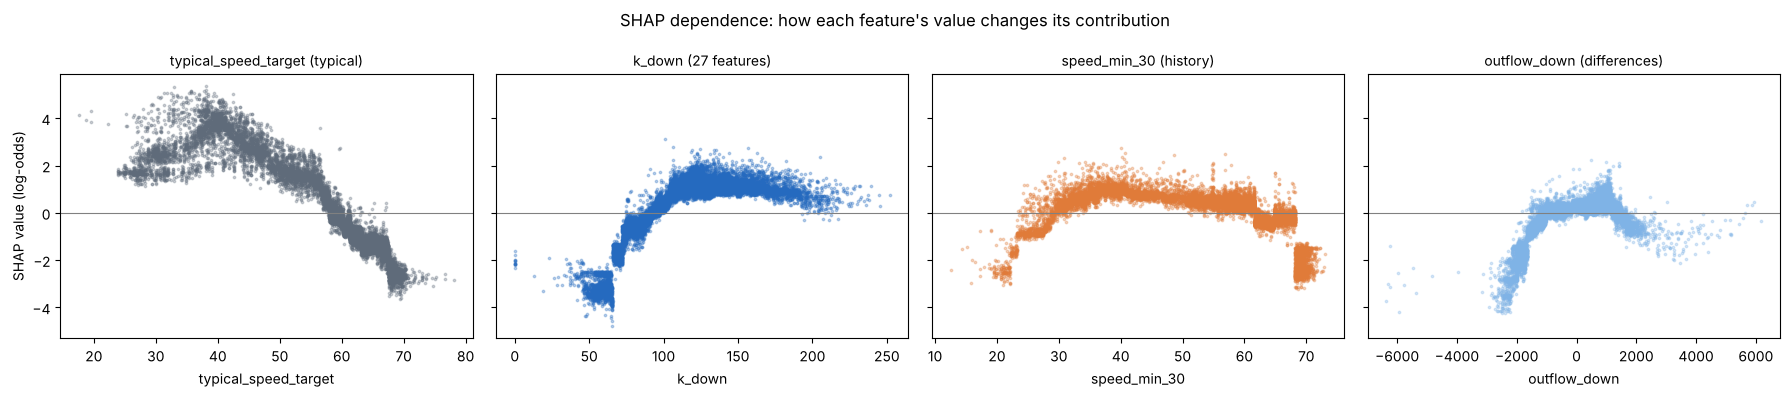

In [16]:
if LGBMClassifier is not None:
    shap_model = LGBMClassifier(n_estimators=N_TREES, learning_rate=0.05, num_leaves=31, verbose=-1, random_state=0)
    shap_model.fit(train_sample[selected], train_sample["label"])
    print(f"LightGBM on the selected features: test AP {average_precision_score(y_test, shap_model.predict_proba(test_all[selected])[:, 1]):.3f}"
          f" (gradient boosting above: {test_table.loc['selected (consistent)', 'AP']:.3f})")

    shap_rows = test_all.sample(min(20_000, len(test_all)), random_state=0).reset_index(drop=True)
    shap_values = pd.DataFrame(shap_model.predict(shap_rows[selected], pred_contrib=True)[:, :-1], columns=selected)
    mean_abs = shap_values.abs().mean().sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(16, max(5, 0.4 * len(selected) + 1.5)), gridspec_kw={"width_ratios": [1, 1.6]})
    axes[0].barh(range(len(mean_abs)), mean_abs.values, color=[group_colors[group_of[f]] for f in mean_abs.index])
    axes[0].set_yticks(range(len(mean_abs)))
    axes[0].set_yticklabels([f"{f} ({group_of[f]})" for f in mean_abs.index], fontsize=8)
    axes[0].set_xlabel("mean |SHAP value| (log-odds)")
    axes[0].set_title("SHAP: overall importance")

    rng = np.random.default_rng(0)
    dots = shap_rows.index[:5_000]                                      # 5,000 rows keep the plot readable
    for k, f in enumerate(mean_abs.index):
        values = shap_rows.loc[dots, f]
        colour = values.rank(pct=True)                                  # low values blue, high values red
        axes[1].scatter(shap_values.loc[dots, f], k + rng.uniform(-0.3, 0.3, len(dots)), c=colour, cmap="coolwarm",
                        s=3, alpha=0.5, vmin=0, vmax=1)
    axes[1].axvline(0, color="grey", linewidth=0.8)
    axes[1].set_yticks(range(len(mean_abs)))
    axes[1].set_yticklabels(mean_abs.index, fontsize=8)
    axes[1].set_xlabel("SHAP value (log-odds): left = lowers the risk, right = raises it")
    axes[1].set_title("SHAP beeswarm (colour = feature value: blue low, red high)")
    colourbar = fig.colorbar(axes[1].collections[0], ax=axes[1], ticks=[0, 1])
    colourbar.ax.set_yticklabels(["low", "high"])
    plt.tight_layout()
    plt.show()

    top4 = list(mean_abs.index[::-1][:4])
    fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
    for ax, f in zip(axes, top4):
        ax.scatter(shap_rows[f], shap_values[f], s=3, alpha=0.3, color=group_colors[group_of[f]])
        ax.axhline(0, color="grey", linewidth=0.8)
        ax.set_xlabel(f)
        ax.set_title(f"{f} ({group_of[f]})", fontsize=10)
    axes[0].set_ylabel("SHAP value (log-odds)")
    fig.suptitle("SHAP dependence: how each feature's value changes its contribution")
    plt.tight_layout()
    plt.show()
else:
    print("SHAP plots skipped: lightgbm is not installed")

## 16. Results in graphs

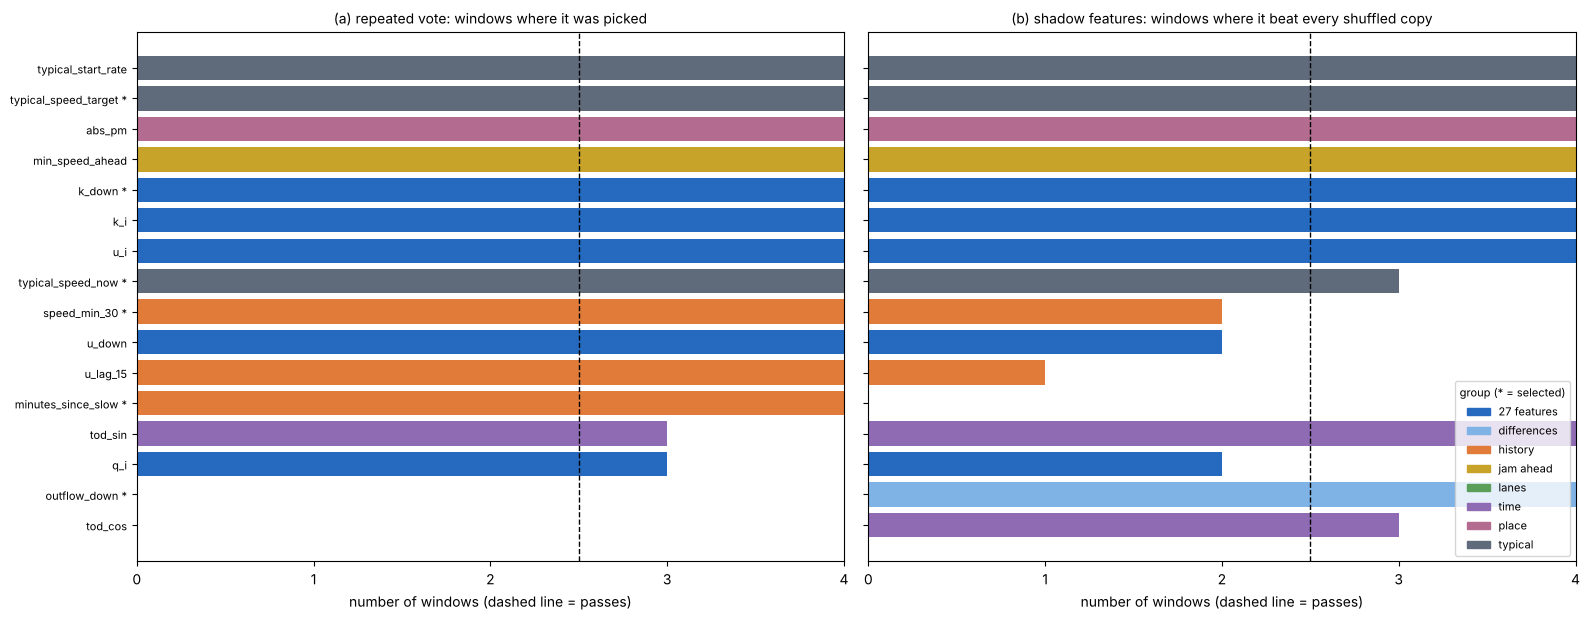

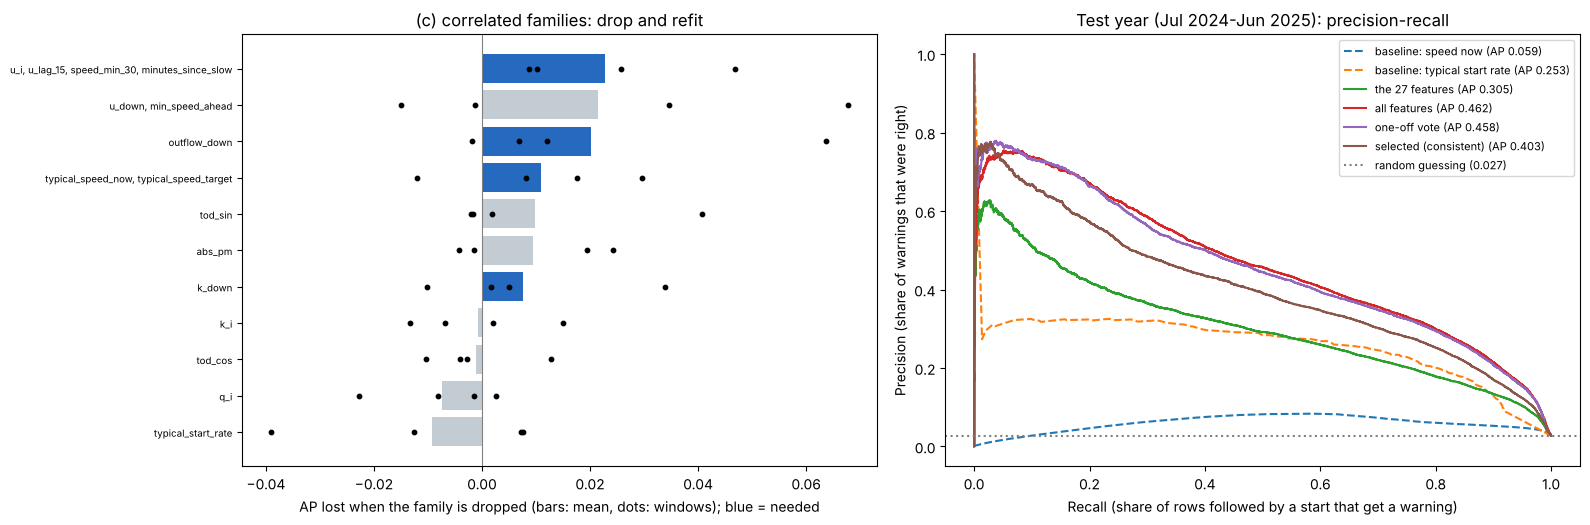

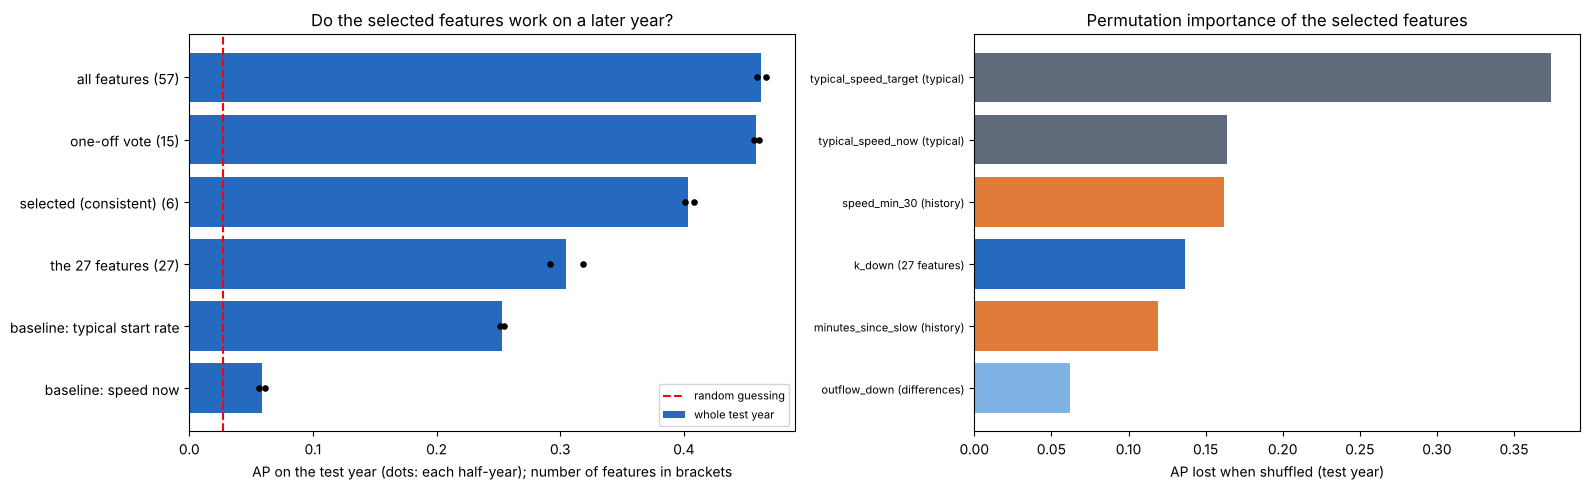

In [17]:
handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in group_colors.values()]

# checks (a) and (b) for every candidate
cand = summary[summary["candidate"]].sort_values(["(a) windows picked", "(b) windows beating shadows"])
fig, axes = plt.subplots(1, 2, figsize=(16, max(5, 0.3 * len(cand) + 1.5)), sharey=True)
y = np.arange(len(cand))
colors = [group_colors[g] for g in cand["group"]]
labels = [f + (" *" if s else "") for f, s in zip(cand.index, cand["selected"])]
for ax, col, title in [(axes[0], "(a) windows picked", "(a) repeated vote: windows where it was picked"),
                       (axes[1], "(b) windows beating shadows", "(b) shadow features: windows where it beat every shuffled copy")]:
    ax.barh(y, cand[col], color=colors)
    ax.axvline(MIN_WINDOWS - 0.5, color="black", linestyle="--", linewidth=1)
    ax.set_xlim(0, len(window_names))
    ax.set_xticks(range(len(window_names) + 1))
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("number of windows (dashed line = passes)")
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=8)
axes[1].legend(handles, list(group_colors), fontsize=8, loc="lower right", title="group (* = selected)", title_fontsize=8)
plt.tight_layout()
plt.show()

# check (c): what each family is worth
fig, axes = plt.subplots(1, 2, figsize=(16, max(4, 0.35 * len(drops) + 1.5)))
d = drops.sort_values("mean AP lost")
axes[0].barh(range(len(d)), d["mean AP lost"], color=["#256abf" if n else "#c3cbd3" for n in d["needed"]])
for k, fam in enumerate(d.index):
    axes[0].scatter(d.loc[fam, window_names].astype(float), [k] * len(window_names), color="black", s=10, zorder=3)
axes[0].axvline(0, color="grey", linewidth=0.8)
axes[0].set_yticks(range(len(d)))
axes[0].set_yticklabels([m if len(m) < 60 else m[:57] + "..." for m in d["members"]], fontsize=7)
axes[0].set_xlabel("AP lost when the family is dropped (bars: mean, dots: windows); blue = needed")
axes[0].set_title("(c) correlated families: drop and refit")

# test year: precision-recall
for name, score in scores_by_set.items():
    p, r, _ = precision_recall_curve(y_test, score)
    style = "--" if name.startswith("baseline") else "-"
    axes[1].plot(r, p, style, label=f"{name} (AP {test_table.loc[name, 'AP']:.3f})")
axes[1].axhline(y_test.mean(), color="grey", linestyle=":", label=f"random guessing ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall (share of rows followed by a start that get a warning)")
axes[1].set_ylabel("Precision (share of warnings that were right)")
axes[1].set_title("Test year (Jul 2024-Jun 2025): precision-recall")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = test_table.sort_values("AP").index
axes[0].barh(range(len(order)), test_table.loc[order, "AP"], color="#256abf", label="whole test year")
for k, name in enumerate(order):
    axes[0].scatter([test_table.loc[name, "AP Jul-Dec 2024"], test_table.loc[name, "AP Jan-Jun 2025"]], [k, k],
                    color="black", s=14, zorder=3)
axes[0].axvline(y_test.mean(), color="red", linestyle="--", label="random guessing")
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels([f"{n} ({int(test_table.loc[n, 'features'])})" if test_table.loc[n, "features"] else n for n in order])
axes[0].set_xlabel("AP on the test year (dots: each half-year); number of features in brackets")
axes[0].set_title("Do the selected features work on a later year?")
axes[0].legend(fontsize=8)

top = importance.head(15)[::-1]
axes[1].barh(range(len(top)), top.values, color=[group_colors[group_of[f]] for f in top.index])
axes[1].set_yticks(range(len(top)))
axes[1].set_yticklabels([f"{f} ({group_of[f]})" for f in top.index], fontsize=8)
axes[1].set_xlabel("AP lost when shuffled (test year)")
axes[1].set_title("Permutation importance of the selected features")
plt.tight_layout()
plt.show()

In [18]:
if SAVE_RESULTS:
    out = ROOT / "results" / "congestion_start_features"
    out.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out / "feature_checks.csv")
    drops.to_csv(out / "family_drops.csv")
    test_table.to_csv(out / "test_year_results.csv")
    pd.Series({"selected_features": selected, "candidates": candidates}).to_json(out / "selected_features.json")
    print("saved to", out)
else:
    print("Results not saved (set SAVE_RESULTS = True to save them).")

Results not saved (set SAVE_RESULTS = True to save them).
